# Validacion de la asignacion (v2): volumen modelado (Visum) vs aforo (IMEPLAN)

Segunda corrida, con los **volumenes de la asignacion ya reducidos**.

**Columnas:**

| Tipo | Columna | Significado |
|---|---|---|
| Visum (asignado) | `VOL_C_<per>` | Volumen asignado de **auto** |
| Visum (asignado) | `VOL_HF_<per>` | Volumen asignado de **carga pesada** |
| Visum (asignado) | `VOL_LF_<per>` | Volumen asignado de **carga ligera** |
| Aforo (real) | `CAR_COUNTS_<per>` | Aforo de **autos** |
| Aforo (real) | `FREIGHT_COUNTS_<per>` | Aforo de **carga** (pesada + ligera juntas) |
| Visum / Aforo | columnas con `TOTAL` | Volumen asignado total y aforo total |

**Dos analisis:**
- **A. Por modo y periodo:** Auto (`VOL_C` vs `CAR_COUNTS`) y Carga (`VOL_HF + VOL_LF` vs `FREIGHT_COUNTS`).
- **B. Totales por periodo:** `VOL ... TOTAL` vs `COUNTS ... TOTAL`.

En todos: solo links con aforo > 0 (0 = sin dato). Se calcula diferencia, error absoluto, % de error y **GEH**.

## 0. Carga de datos

In [11]:
import re
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = "/Users/ebonyvaladez/Desktop/Septimo/on campus/links asignacion"   # <-- cambiar a la ruta del archivo nuevo
PERIODOS = ["AP", "LM", "EA", "PP"]
HORAS = {"AP": 5, "LM": 3, "EA": 6, "PP": 3}       # duracion de cada periodo (tabla de periodos)
GEH_BASE = "GEH_hora"                              # "GEH_hora" o "GEH_periodo"

gdf = gpd.read_file(RUTA)
print(gdf.shape)
print(gdf.columns.tolist())

(228360, 32)
['NO', 'FROMNODENO', 'TONODENO', 'CAR_COUN~1', 'VOL_C_AP', 'FREIGHT_~2', 'VOL_HF_AP', 'VOL_LF_AP', 'CAR_COUN~3', 'VOL_C_LM', 'FREIGHT_~4', 'VOL_HF_LM', 'VOL_LF_LM', 'CAR_COUN~5', 'VOL_C_EA', 'FREIGHT_~6', 'VOL_HF_EA', 'VOL_LF_EA', 'CAR_COUN~7', 'VOL_C_PP', 'FREIGHT_~8', 'VOL_HF_PP', 'VOL_LF_PP', 'TOTAL_CO~9', 'TOTAL_V~10', 'TOTAL_C~11', 'TOTAL_V~12', 'TOTAL_C~13', 'TOTAL_V~14', 'TOTAL_C~15', 'TOTAL_V~16', 'geometry']


## 1. Identificar las columnas
Se buscan por nombre. **Revisa la tabla que se imprime**: cada fila debe apuntar a la columna correcta.

Si alguna sale como `NO ENCONTRADA`, escribe el nombre real en `MANUAL`.

In [12]:
# Si algo no se encuentra, escribirlo aqui, por ejemplo:  MANUAL = {"aforo_total_AP": "COUNTS_TOT~1"}
MANUAL = {
    "aforo_auto_AP": "CAR_COUN~1", "aforo_carga_AP": "FREIGHT_~2",
    "aforo_auto_LM": "CAR_COUN~3", "aforo_carga_LM": "FREIGHT_~4",
    "aforo_auto_EA": "CAR_COUN~5", "aforo_carga_EA": "FREIGHT_~6",
    "aforo_auto_PP": "CAR_COUN~7", "aforo_carga_PP": "FREIGHT_~8",

    "aforo_total_AP": "TOTAL_CO~9",  "vol_total_AP": "TOTAL_V~10",
    "aforo_total_LM": "TOTAL_C~11",  "vol_total_LM": "TOTAL_V~12",
    "aforo_total_EA": "TOTAL_C~13",  "vol_total_EA": "TOTAL_V~14",
    "aforo_total_PP": "TOTAL_C~15",  "vol_total_PP": "TOTAL_V~16",
}

cols_up = {c.upper(): c for c in gdf.columns}

def exacta(nombre):
    return cols_up.get(nombre.upper())

def buscar_total(p, quiere_counts):
    """Columna que contiene TOTAL y el periodo; con COUNT (aforo) o sin COUNT (Visum)."""
    cands = [c for c in gdf.columns
             if "TOTAL" in c.upper()
             and re.search(rf"(^|_){p}($|_)", c.upper())
             and (("COUNT" in c.upper()) == quiere_counts)]
    return cands[0] if len(cands) == 1 else (cands if cands else None)

COL = {}
for p in PERIODOS:
    COL[f"vol_auto_{p}"]    = exacta(f"VOL_C_{p}")
    COL[f"vol_hf_{p}"]      = exacta(f"VOL_HF_{p}")
    COL[f"vol_lf_{p}"]      = exacta(f"VOL_LF_{p}")
    COL[f"aforo_auto_{p}"]  = exacta(f"CAR_COUNTS_{p}")
    COL[f"aforo_carga_{p}"] = exacta(f"FREIGHT_COUNTS_{p}")
    COL[f"vol_total_{p}"]   = buscar_total(p, quiere_counts=False)
    COL[f"aforo_total_{p}"] = buscar_total(p, quiere_counts=True)
COL.update(MANUAL)

revision = pd.DataFrame([
    {"variable": k,
     "columna_en_archivo": v if isinstance(v, str) else ("NO ENCONTRADA" if v is None else f"AMBIGUA: {v}")}
    for k, v in COL.items()])
print(revision.to_string(index=False))

faltan = revision[~revision["columna_en_archivo"].isin(gdf.columns)]
if len(faltan):
    print("\n>>> Revisar/llenar en MANUAL:", faltan["variable"].tolist())

      variable columna_en_archivo
   vol_auto_AP           VOL_C_AP
     vol_hf_AP          VOL_HF_AP
     vol_lf_AP          VOL_LF_AP
 aforo_auto_AP         CAR_COUN~1
aforo_carga_AP         FREIGHT_~2
  vol_total_AP         TOTAL_V~10
aforo_total_AP         TOTAL_CO~9
   vol_auto_LM           VOL_C_LM
     vol_hf_LM          VOL_HF_LM
     vol_lf_LM          VOL_LF_LM
 aforo_auto_LM         CAR_COUN~3
aforo_carga_LM         FREIGHT_~4
  vol_total_LM         TOTAL_V~12
aforo_total_LM         TOTAL_C~11
   vol_auto_EA           VOL_C_EA
     vol_hf_EA          VOL_HF_EA
     vol_lf_EA          VOL_LF_EA
 aforo_auto_EA         CAR_COUN~5
aforo_carga_EA         FREIGHT_~6
  vol_total_EA         TOTAL_V~14
aforo_total_EA         TOTAL_C~13
   vol_auto_PP           VOL_C_PP
     vol_hf_PP          VOL_HF_PP
     vol_lf_PP          VOL_LF_PP
 aforo_auto_PP         CAR_COUN~7
aforo_carga_PP         FREIGHT_~8
  vol_total_PP         TOTAL_V~16
aforo_total_PP         TOTAL_C~15


## 2. Construir variables limpias

In [13]:
def v(nombre):
    c = COL[nombre]
    return pd.to_numeric(gdf[c], errors="coerce").fillna(0) if isinstance(c, str) and c in gdf.columns else None

df = pd.DataFrame({"NO": gdf["NO"], "FROMNODENO": gdf["FROMNODENO"], "TONODENO": gdf["TONODENO"]})
if "TYPENO" in gdf.columns:
    df["TYPENO"] = gdf["TYPENO"]

for p in PERIODOS:
    for nombre in ["vol_auto", "vol_hf", "vol_lf", "aforo_auto", "aforo_carga", "vol_total", "aforo_total"]:
        serie = v(f"{nombre}_{p}")
        if serie is not None:
            df[f"{nombre}_{p}"] = serie
    if f"vol_hf_{p}" in df and f"vol_lf_{p}" in df:
        df[f"vol_carga_{p}"] = df[f"vol_hf_{p}"] + df[f"vol_lf_{p}"]     # carga modelada = HF + LF

# Filtro: links que permiten auto ("C" en TSYSSET), igual que en la primera version
if "TSYSSET" in gdf.columns:
    modos = gdf["TSYSSET"].fillna("").astype(str).str.split(",")
    df["PERMITE_AUTO"] = modos.apply(lambda s: "C" in [x.strip() for x in s])
else:
    df["PERMITE_AUTO"] = True
    print("No hay columna TSYSSET: se usan todos los links.")

links = df[df["PERMITE_AUTO"]].copy()
print(f"Total links: {len(df):,} | Links que permiten auto: {len(links):,}")

No hay columna TSYSSET: se usan todos los links.
Total links: 228,360 | Links que permiten auto: 228,360


### Revision rapida: ¿el TOTAL es la suma de los modos?
Si el total de Visum = auto + HF + LF y el aforo total = aforo auto + aforo carga, la diferencia deberia ser ~0.

In [14]:
chequeo = []
for p in PERIODOS:
    fila = {"periodo": p}
    if all(f"{x}_{p}" in links for x in ["vol_total", "vol_auto", "vol_carga"]):
        d = links[f"vol_total_{p}"] - (links[f"vol_auto_{p}"] + links[f"vol_carga_{p}"])
        fila["vol_total = auto+HF+LF (% links)"] = round((d.abs() < 1).mean() * 100, 1)
    if all(f"{x}_{p}" in links for x in ["aforo_total", "aforo_auto", "aforo_carga"]):
        d = links[f"aforo_total_{p}"] - (links[f"aforo_auto_{p}"] + links[f"aforo_carga_{p}"])
        fila["aforo_total = auto+carga (% links)"] = round((d.abs() < 1).mean() * 100, 1)
    chequeo.append(fila)
pd.DataFrame(chequeo)

,periodo,vol_total = auto+HF+LF (% links),aforo_total = auto+carga (% links)
0,AP,97.2,99.6
1,LM,96.7,99.6
2,EA,95.8,99.6
3,PP,97.4,99.6


## 3. Tabla resumen de links

In [15]:
tabla_resumen_links = pd.DataFrame({
    "total_links": len(df),
    "links_permiten_auto": len(links),
    "links_con_aforo_auto":  [(links[f"aforo_auto_{p}"] > 0).sum()  if f"aforo_auto_{p}" in links else np.nan for p in PERIODOS],
    "links_con_aforo_carga": [(links[f"aforo_carga_{p}"] > 0).sum() if f"aforo_carga_{p}" in links else np.nan for p in PERIODOS],
    "links_con_aforo_total": [(links[f"aforo_total_{p}"] > 0).sum() if f"aforo_total_{p}" in links else np.nan for p in PERIODOS],
}, index=pd.Index(PERIODOS, name="periodo"))
tabla_resumen_links

,total_links,links_permiten_auto,links_con_aforo_auto,links_con_aforo_carga,links_con_aforo_total
periodo,,,,,
AP,228360,228360,294,202,541
LM,228360,228360,294,249,540
EA,228360,228360,292,249,542
PP,228360,228360,293,180,541


In [29]:
for p in PERIODOS:
    con_total = links[f"aforo_total_{p}"] > 0
    con_desglose = (links[f"aforo_auto_{p}"] > 0) | (links[f"aforo_carga_{p}"] > 0)
    print(p, "| con desglose:", (con_total & con_desglose).sum(),
          "| solo total:", (con_total & ~con_desglose).sum())

AP | con desglose: 29 | solo total: 512
LM | con desglose: 29 | solo total: 511
EA | con desglose: 29 | solo total: 513
PP | con desglose: 29 | solo total: 512


In [30]:
for p in PERIODOS:
    ambas = links[(links[f"aforo_total_{p}"] > 0) &
                  ((links[f"aforo_auto_{p}"] > 0) | (links[f"aforo_carga_{p}"] > 0))]
    suma = ambas[f"aforo_auto_{p}"] + ambas[f"aforo_carga_{p}"]
    cuadra = ((ambas[f"aforo_total_{p}"] - suma).abs() < 1).mean() * 100
    print(p, "| calles:", len(ambas), "| total = auto+carga en", round(cuadra, 1), "%")

AP | calles: 29 | total = auto+carga en 0.0 %
LM | calles: 29 | total = auto+carga en 3.4 %
EA | calles: 29 | total = auto+carga en 0.0 %
PP | calles: 29 | total = auto+carga en 0.0 %


## 4. Funciones: tabla por link, GEH y resumen

$GEH = \\sqrt{\\dfrac{2(M-C)^2}{M+C}}$, con **M = modelado (Visum)** y **C = aforo**.
GEH < 5 bien | 5-10 regular | > 10 mal. Meta usual: 85 % de links con GEH < 5.

- `GEH_periodo`: con el volumen del periodo tal cual.
- `GEH_hora`: dividiendo entre las horas del periodo (los umbrales 5 y 10 estan pensados por hora).

In [16]:
def geh(m, c):
    return np.sqrt(2 * (m - c) ** 2 / (m + c))

def tabla_por_link(base, aforo, modelado, modo, extra=()):
    partes = []
    for p in PERIODOS:
        if f"{aforo}_{p}" not in base or f"{modelado}_{p}" not in base:
            continue
        sub = base[base[f"{aforo}_{p}"] > 0]
        t = sub[[c for c in ["NO", "FROMNODENO", "TONODENO", "TYPENO"] if c in sub]].copy()
        t["modo"] = modo
        t["periodo"] = p
        t["vol_observado"] = sub[f"{aforo}_{p}"]
        for e in extra:
            if f"{e}_{p}" in sub:
                t[e] = sub[f"{e}_{p}"]
        t["vol_modelado"] = sub[f"{modelado}_{p}"]
        t["diferencia"] = t["vol_modelado"] - t["vol_observado"]
        t["error_absoluto"] = t["diferencia"].abs()
        t["pct_error"] = t["diferencia"] / t["vol_observado"] * 100
        t["GEH_periodo"] = geh(t["vol_modelado"], t["vol_observado"])
        t["GEH_hora"] = geh(t["vol_modelado"] / HORAS[p], t["vol_observado"] / HORAS[p])
        t["GEH"] = t[GEH_BASE]
        t["rango_GEH"] = pd.cut(t["GEH"], [-np.inf, 5, 10, np.inf], right=False,
                                labels=["< 5", "5 - 10", "> 10"])
        partes.append(t)
    return pd.concat(partes, ignore_index=True).round(2) if partes else pd.DataFrame()

def resumir(t):
    g = t.groupby(["modo", "periodo"], sort=False)
    r = pd.DataFrame({
        "links_con_aforo": g.size(),
        "vol_observado_total": g["vol_observado"].sum(),
        "vol_modelado_total": g["vol_modelado"].sum(),
        "GEH_promedio": g["GEH"].mean(),
        "GEH_mediana": g["GEH"].median(),
        "n_GEH<5":    g["GEH"].apply(lambda x: (x < 5).sum()),
        "n_GEH_5a10": g["GEH"].apply(lambda x: ((x >= 5) & (x < 10)).sum()),
        "n_GEH>10":   g["GEH"].apply(lambda x: (x >= 10).sum()),
        "sesgo_promedio": g["diferencia"].mean(),
        "pct_error_mediana": g["pct_error"].median(),
    })
    r["dif_total_%"] = (r["vol_modelado_total"] - r["vol_observado_total"]) / r["vol_observado_total"] * 100
    for col in ["n_GEH<5", "n_GEH_5a10", "n_GEH>10"]:
        r["%" + col[1:]] = r[col] / r["links_con_aforo"] * 100
    r["cumple_85%"] = r["%_GEH<5"] >= 85
    r["R2"] = g.apply(lambda x: np.corrcoef(x["vol_modelado"], x["vol_observado"])[0, 1] ** 2
                      if len(x) > 1 else np.nan)
    return r.round(2)

## A. Analisis por modo y periodo
- **Auto:** `VOL_C` vs `CAR_COUNTS`
- **Carga:** `VOL_HF + VOL_LF` vs `FREIGHT_COUNTS`

In [17]:
tabla_auto  = tabla_por_link(links, "aforo_auto",  "vol_auto",  "Auto")
tabla_carga = tabla_por_link(links, "aforo_carga", "vol_carga", "Carga (HF+LF)", extra=("vol_hf", "vol_lf"))
tabla_auto.head(15)

,NO,FROMNODENO,TONODENO,modo,periodo,vol_observado,vol_modelado,diferencia,error_absoluto,pct_error,GEH_periodo,GEH_hora,GEH,rango_GEH
0,95755,37902,44413,Auto,AP,7,827,820,820,11714.29,40.16,17.96,17.96,> 10
1,95757,37903,37902,Auto,AP,6,849,843,843,14050.00,40.77,18.23,18.23,> 10
2,96016,38015,76091,Auto,AP,7,41,34,34,485.71,6.94,3.10,3.10,< 5
3,96016,76091,38015,Auto,AP,475,544,69,69,14.53,3.06,1.37,1.37,< 5
4,96017,38015,44453,Auto,AP,296,267,-29,29,-9.80,1.73,0.77,0.77,< 5
5,97144,38527,38667,Auto,AP,79,46,-33,33,-41.77,4.17,1.87,1.87,< 5
6,97145,38527,38538,Auto,AP,34,85,51,51,150.00,6.61,2.96,2.96,< 5
7,97279,38584,38527,Auto,AP,63,0,-63,63,-100.00,11.22,5.02,5.02,5 - 10
8,97348,38612,38527,Auto,AP,146,131,-15,15,-10.27,1.27,0.57,0.57,< 5
9,97440,38654,38686,Auto,AP,59,1338,1279,1279,2167.80,48.39,21.64,21.64,> 10


In [18]:
tabla_carga.head(15)

,NO,FROMNODENO,TONODENO,modo,periodo,vol_observado,vol_hf,vol_lf,vol_modelado,diferencia,error_absoluto,pct_error,GEH_periodo,GEH_hora,GEH,rango_GEH
0,96016,38015,76091,Carga (HF+LF),AP,4,0,0,0,-4,4,-100.00,2.83,1.26,1.26,< 5
1,96016,76091,38015,Carga (HF+LF),AP,15,0,0,0,-15,15,-100.00,5.48,2.45,2.45,< 5
2,97145,38527,38538,Carga (HF+LF),AP,1,0,0,0,-1,1,-100.00,1.41,0.63,0.63,< 5
3,97279,38584,38527,Carga (HF+LF),AP,2,0,0,0,-2,2,-100.00,2.00,0.89,0.89,< 5
4,97348,38612,38527,Carga (HF+LF),AP,2,0,0,0,-2,2,-100.00,2.00,0.89,0.89,< 5
5,97655,38757,104530,Carga (HF+LF),AP,1,0,0,0,-1,1,-100.00,1.41,0.63,0.63,< 5
6,97656,38757,202300,Carga (HF+LF),AP,10,0,0,0,-10,10,-100.00,4.47,2.00,2.00,< 5
7,97677,38767,38781,Carga (HF+LF),AP,1,0,0,0,-1,1,-100.00,1.41,0.63,0.63,< 5
8,97692,38781,38774,Carga (HF+LF),AP,1,0,0,0,-1,1,-100.00,1.41,0.63,0.63,< 5
9,97783,38809,38781,Carga (HF+LF),AP,1,0,0,0,-1,1,-100.00,1.41,0.63,0.63,< 5


In [19]:
resumen_modo = resumir(pd.concat([tabla_auto, tabla_carga]))
resumen_modo

/var/folders/7v/7hgznyg12hbblt4_0ndcjbdr0000gn/T/ipykernel_53363/1424951197.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r["R2"] = g.apply(lambda x: np.corrcoef(x["vol_modelado"], x["vol_observado"])[0, 1] ** 2


links_con_aforo  vol_observado_total  \
modo          periodo                                         
Auto          AP                   294               147109   
              LM                   294               159923   
              EA                   292               187655   
              PP                   293               205779   
Carga (HF+LF) AP                   202                 1116   
              LM                   249                 1992   
              EA                   249                 1980   
              PP                   180                  978   

                       vol_modelado_total  GEH_promedio  GEH_mediana  n_GEH<5  \
modo          periodo                                                           
Auto          AP                   149081          7.48         5.86      127   
              LM                    68187         10.51         8.70       82   
              EA                   124886          7.13         5.97      124   
              PP                   124947         11.31         9.47       72   
Carga (HF+LF) AP                      711          1.28         1.10      199   
              LM                     1315          1.88         1.55      244   
              EA                     1054          1.29         1.00      246   
              PP                      513          1.45         1.28      178   

                       n_GEH_5a10  n_GEH>10  sesgo_promedio  \
modo          periodo                                         
Auto          AP               90        77            6.71   
              LM               88       124         -312.03   
              EA               93        75         -214.96   
              PP               87       134         -275.88   
Carga (HF+LF) AP                3         0           -2.00   
              LM                3         2           -2.72   
              EA                3         0           -3.72   
              PP                2         0           -2.58   

                       pct_error_mediana  dif_total_%  %_GEH<5  %_GEH_5a10  \
modo          periodo                                                        
Auto          AP                  -21.97         1.34    43.20       30.61   
              LM                  -73.40       -57.36    27.89       29.93   
              EA                  -51.34       -33.45    42.47       31.85   
              PP                  -66.27       -39.28    24.57       29.69   
Carga (HF+LF) AP                 -100.00       -36.29    98.51        1.49   
              LM                 -100.00       -33.99    97.99        1.20   
              EA                 -100.00       -46.77    98.80        1.20   
              PP                 -100.00       -47.55    98.89        1.11   

                       %_GEH>10  cumple_85%    R2  
modo          periodo                              
Auto          AP          26.19       False  0.31  
              LM          42.18       False  0.34  
              EA          25.68       False  0.37  
              PP          45.73       False  0.35  
Carga (HF+LF) AP           0.00        True  0.07  
              LM           0.80        True  0.10  
              EA           0.00        True  0.10  
              PP           0.00        True  0.23

## B. Analisis de TOTALES por periodo
`VOL ... TOTAL` (Visum) vs `COUNTS ... TOTAL` (aforo), solo donde el aforo total > 0.

In [20]:
tabla_total = tabla_por_link(links, "aforo_total", "vol_total", "Total")
resumen_total = resumir(tabla_total) if len(tabla_total) else pd.DataFrame()
resumen_total

/var/folders/7v/7hgznyg12hbblt4_0ndcjbdr0000gn/T/ipykernel_53363/1424951197.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r["R2"] = g.apply(lambda x: np.corrcoef(x["vol_modelado"], x["vol_observado"])[0, 1] ** 2


links_con_aforo  vol_observado_total  vol_modelado_total  \
modo  periodo                                                             
Total AP                   541            779096.58              622795   
      LM                   540            682721.38              294251   
      EA                   542            815051.35              534447   
      PP                   541            899198.00              534291   

               GEH_promedio  GEH_mediana  n_GEH<5  n_GEH_5a10  n_GEH>10  \
modo  periodo                                                             
Total AP               9.81         7.87      193         147       201   
      LM              15.18        13.50       94          93       353   
      EA               9.61         8.10      178         139       225   
      PP              15.14        12.81      109         113       319   

               sesgo_promedio  pct_error_mediana  dif_total_%  %_GEH<5  \
modo  periodo                                                            
Total AP              -288.91             -15.70       -20.06    35.67   
      LM              -719.39             -58.17       -56.90    17.41   
      EA              -517.72             -37.39       -34.43    32.84   
      PP              -674.50             -44.16       -40.58    20.15   

               %_GEH_5a10  %_GEH>10  cumple_85%    R2  
modo  periodo                                          
Total AP            27.17     37.15       False  0.08  
      LM            17.22     65.37       False  0.06  
      EA            25.65     41.51       False  0.10  
      PP            20.89     58.96       False  0.10

## 5. Estadisticas basicas
Promedio, mediana, minimo, maximo y percentiles. La **mediana** es mas confiable que el promedio cuando hay calles con errores enormes.

In [21]:
todo = pd.concat([tabla_auto, tabla_carga, tabla_total], ignore_index=True)
cols_stats = ["vol_observado", "vol_modelado", "diferencia", "pct_error", "GEH"]
stats_basicas = (todo.groupby(["modo", "periodo"], sort=False)[cols_stats]
                 .describe(percentiles=[.25, .5, .75])
                 .stack(level=0, future_stack=True)
                 .rename_axis(["modo", "periodo", "variable"])
                 .rename(columns={"count": "n", "mean": "promedio", "std": "desv_std", "min": "minimo",
                                  "25%": "p25", "50%": "mediana", "75%": "p75", "max": "maximo"})
                 .round(2))
stats_basicas

n  promedio  desv_std    minimo  \
modo          periodo variable                                             
Auto          AP      vol_observado  294.0    500.37    640.93      1.00   
                      vol_modelado   294.0    507.08    649.40      0.00   
                      diferencia     294.0      6.71    609.44  -2796.00   
                      pct_error      294.0    571.66   2965.38   -100.00   
                      GEH            294.0      7.48      6.13      0.06   
              LM      vol_observado  294.0    543.96    650.87      1.00   
                      vol_modelado   294.0    231.93    324.72      0.00   
                      diferencia     294.0   -312.03    531.28  -2870.00   
                      pct_error      294.0    208.85   2259.61   -100.00   
                      GEH            294.0     10.51      7.94      0.00   
              EA      vol_observado  292.0    642.65    745.32      1.00   
                      vol_modelado   292.0    427.69    558.84      0.00   
                      diferencia     292.0   -214.96    600.56  -2590.00   
                      pct_error      292.0    452.67   3960.12   -100.00   
                      GEH            292.0      7.13      5.50      0.12   
              PP      vol_observado  293.0    702.32    816.04      1.00   
                      vol_modelado   293.0    426.44    572.20      0.00   
                      diferencia     293.0   -275.88    666.31  -3195.00   
                      pct_error      293.0    440.11   3582.86   -100.00   
                      GEH            293.0     11.31      8.23      0.10   
Carga (HF+LF) AP      vol_observado  202.0      5.52      5.89      1.00   
                      vol_modelado   202.0      3.52     21.27      0.00   
                      diferencia     202.0     -2.00     20.47    -27.00   
                      pct_error      202.0    -44.72    311.33   -100.00   
                      GEH            202.0      1.28      1.01      0.00   
              LM      vol_observado  249.0      8.00      9.53      1.00   
                      vol_modelado   249.0      5.28     27.01      0.00   
                      diferencia     249.0     -2.72     25.59    -47.00   
                      pct_error      249.0     -4.69    479.25   -100.00   
                      GEH            249.0      1.88      1.47      0.00   
              EA      vol_observado  249.0      7.95      9.49      1.00   
                      vol_modelado   249.0      4.23     21.09      0.00   
                      diferencia     249.0     -3.72     20.24    -41.00   
                      pct_error      249.0    -12.06    552.00   -100.00   
                      GEH            249.0      1.29      0.96      0.00   
              PP      vol_observado  180.0      5.43      6.49      1.00   
                      vol_modelado   180.0      2.85     12.85      0.00   
                      diferencia     180.0     -2.58     11.27    -23.00   
                      pct_error      180.0    -51.72    204.10   -100.00   
                      GEH            180.0      1.45      1.01      0.00   
Total         AP      vol_observado  541.0   1440.10   1499.45      0.74   
                      vol_modelado   541.0   1151.19    922.18      0.00   
                      diferencia     541.0   -288.91   1520.63 -19926.13   
                      pct_error      541.0    343.45   6539.49   -100.00   
                      GEH            541.0      9.81      9.26      0.06   
              LM      vol_observado  540.0   1264.30    975.44      6.17   
                      vol_modelado   540.0    544.91    423.31      0.00   
                      diferencia     540.0   -719.39    965.19 -11445.28   
                      pct_error      540.0     -4.46    696.16   -100.00   
                      GEH            540.0     15.18     10.55      0.00   
              EA      vol_observado  542.0   1503.78   1080.74      0.19   
             

## 6. Error segun el nivel de trafico observado
Se agrupan las calles por **cuantos vehiculos se contaron**. Permite ver si el modelo falla igual en calles con poco y con mucho trafico.

In [37]:
CORTES = [0, 100, 250, 500, 1000, np.inf]
ETIQ = ["1-100", "101-250", "251-500", "501-1000", "> 1000"]
todo["nivel_trafico"] = pd.cut(todo["vol_observado"], CORTES, labels=ETIQ)

def resumen_grupo(t, col):
    g = t.groupby(["modo", col], observed=True, sort=False)
    return pd.DataFrame({
        "n_calles": g.size(),
        "vol_observado_prom": g["vol_observado"].mean(),
        "vol_modelado_prom": g["vol_modelado"].mean(),
        "sesgo_promedio": g["diferencia"].mean(),
        "pct_error_mediana": g["pct_error"].median(),
        "GEH_promedio": g["GEH"].mean(),
        "%_GEH<5":  g["GEH"].apply(lambda x: (x < 5).mean() * 100),
        "%_GEH>10": g["GEH"].apply(lambda x: (x >= 10).mean() * 100),
    }).round(2).reset_index()

error_nivel = resumen_grupo(todo, "nivel_trafico")
error_nivel["nivel_trafico"] = pd.Categorical(error_nivel["nivel_trafico"], categories=ETIQ, ordered=True)
error_nivel = error_nivel.sort_values(["modo", "nivel_trafico"]).reset_index(drop=True)

error_nivel

,modo,nivel_trafico,n_calles,vol_observado_prom,vol_modelado_prom,sesgo_promedio,pct_error_mediana,GEH_promedio,%_GEH<5,%_GEH>10
0,Auto,1-100,326,45.06,175.06,130.01,-27.71,6.33,52.15,15.95
1,Auto,101-250,222,159.48,129.60,-29.88,-77.37,6.69,37.39,17.57
2,Auto,251-500,163,353.68,297.26,-56.42,-67.10,9.34,23.93,44.79
3,Auto,501-1000,213,727.64,451.93,-275.71,-56.14,10.23,26.76,48.83
4,Auto,> 1000,249,1757.98,949.98,-808.00,-50.22,13.80,22.49,57.03
5,Carga (HF+LF),1-100,880,6.89,4.08,-2.81,-100.00,1.49,98.52,0.23
6,Total,1-100,42,50.62,479.43,428.81,452.46,11.47,23.81,45.24
7,Total,101-250,84,185.70,436.45,250.75,20.76,8.13,41.67,25.00
8,Total,251-500,218,371.44,677.95,306.52,21.70,9.70,33.03,41.74
9,Total,501-1000,507,750.05,664.21,-85.84,-34.40,9.43,29.78,41.81


## 7. Error segun el tipo de calle (`TYPENO`)

In [38]:
error_tipo = (resumen_grupo(todo, "TYPENO").sort_values(["modo", "n_calles"], ascending=[True, False])
              if "TYPENO" in todo else pd.DataFrame())
error_tipo

""


## 8. Graficas
**Puntos observado vs modelado:** cada punto es una calle. Arriba de la linea = Visum puso de mas; abajo = de menos. Color = rango GEH.

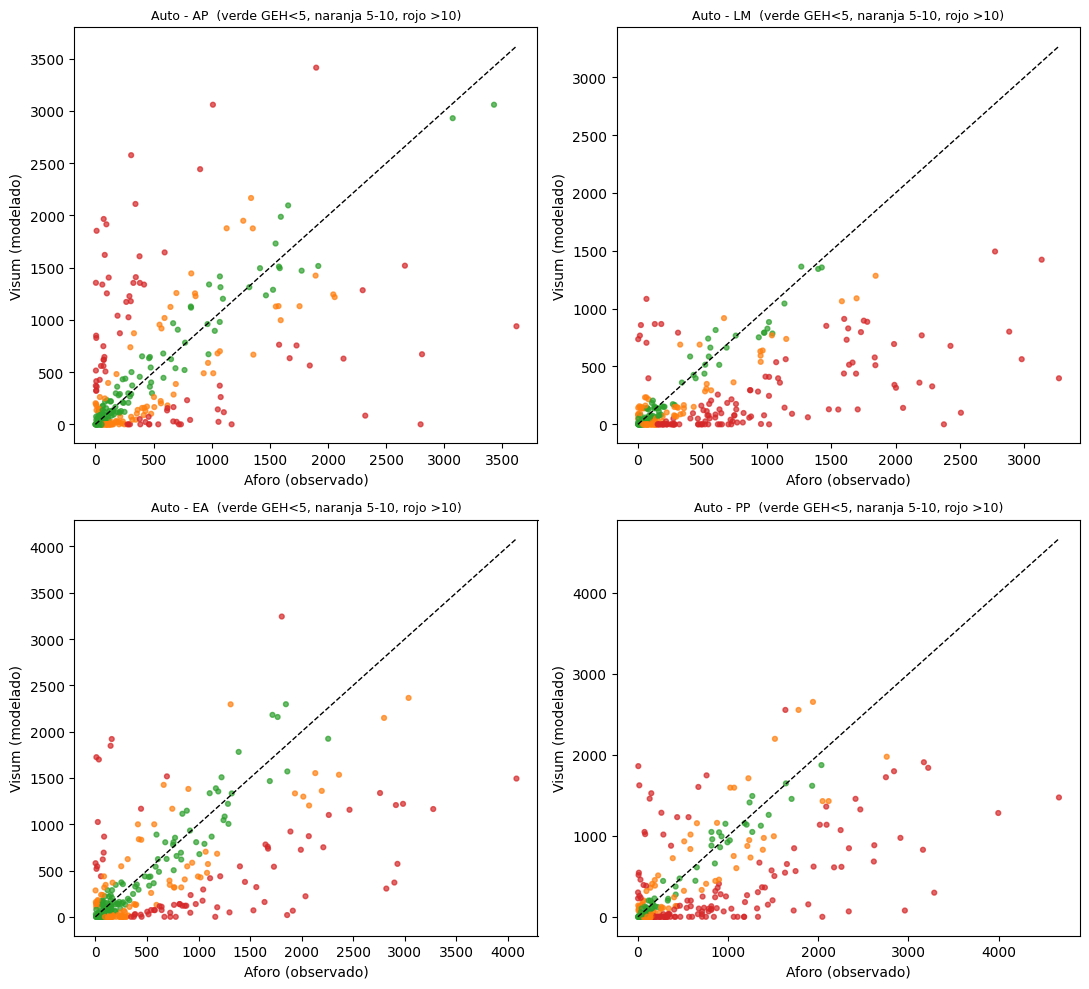

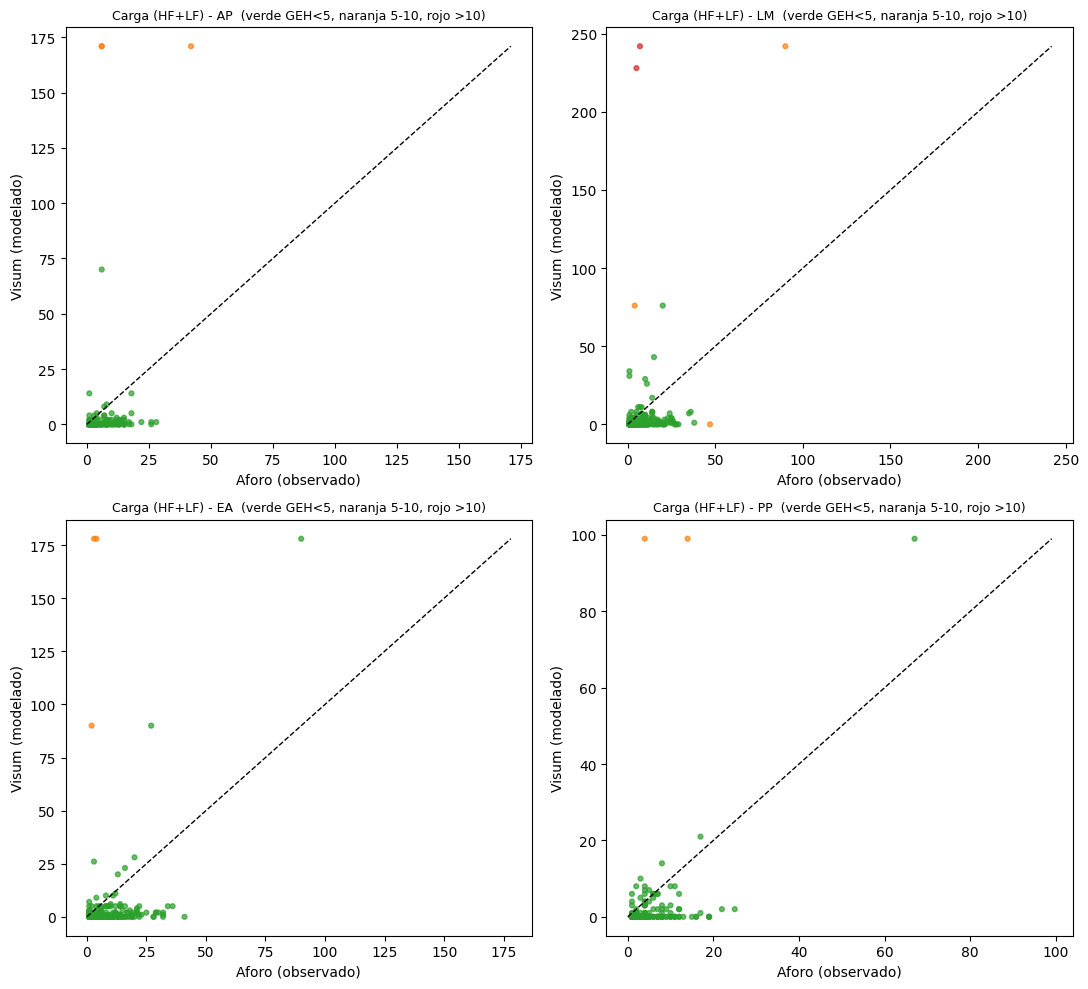

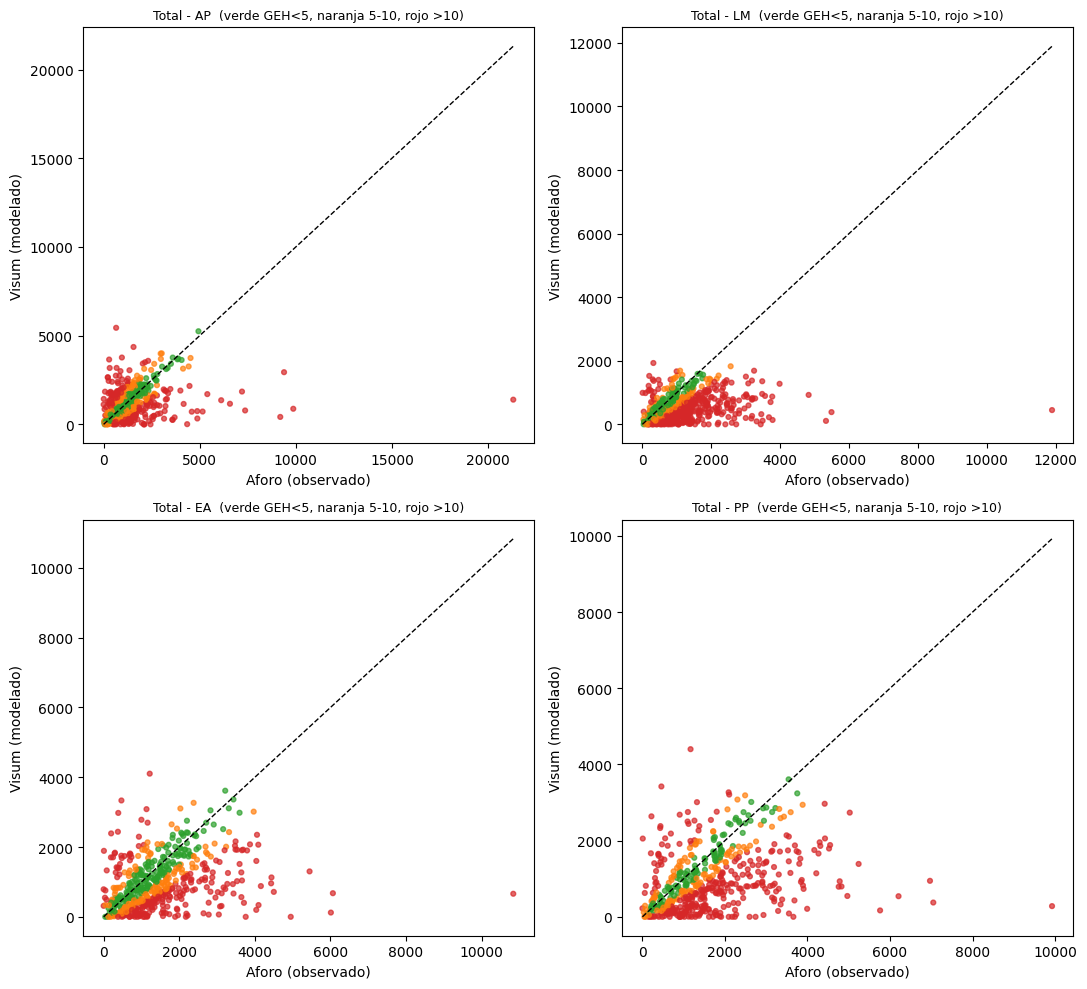

In [39]:
COLORES_GEH = {"< 5": "tab:green", "5 - 10": "tab:orange", "> 10": "tab:red"}

def dispersion(t, titulo):
    if t.empty: return
    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    for ax, p in zip(axes.flat, PERIODOS):
        d = t[t["periodo"] == p]
        if d.empty: ax.set_visible(False); continue
        ax.scatter(d["vol_observado"], d["vol_modelado"], c=d["rango_GEH"].map(COLORES_GEH), s=12, alpha=0.7)
        lim = max(d["vol_observado"].max(), d["vol_modelado"].max())
        ax.plot([0, lim], [0, lim], "k--", lw=1)
        #ax.set_xlim(0, 3500); ax.set_ylim(0, 3500)
        ax.set_title(f"{titulo} - {p}  (verde GEH<5, naranja 5-10, rojo >10)", fontsize=9)
        ax.set_xlabel("Aforo (observado)"); ax.set_ylabel("Visum (modelado)")
    plt.tight_layout(); plt.show()

dispersion(tabla_auto, "Auto")
dispersion(tabla_carga, "Carga (HF+LF)")
dispersion(tabla_total, "Total")

**% de links por rango de GEH** (la linea punteada es la meta de 85 %):

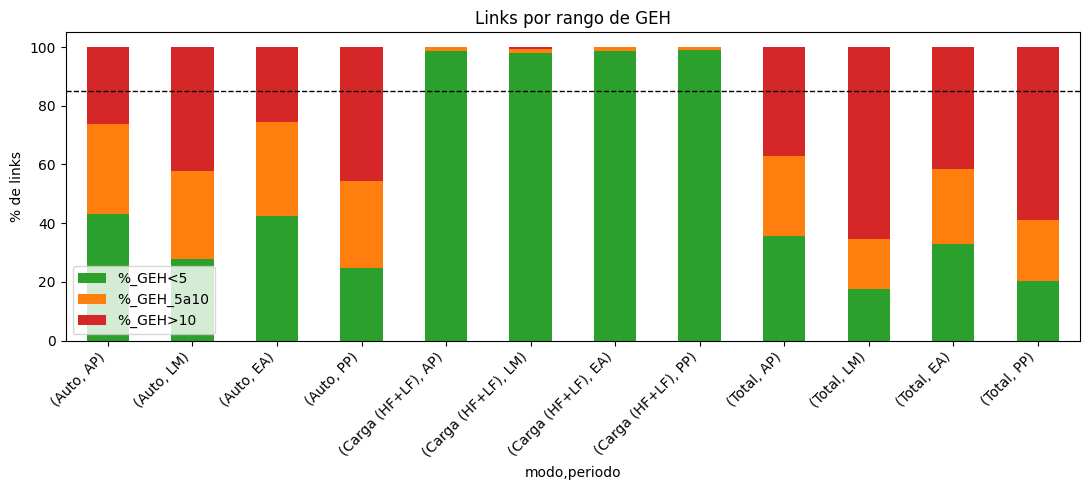

In [40]:
res_todo = pd.concat([resumen_modo, resumen_total])
pct = res_todo[["%_GEH<5", "%_GEH_5a10", "%_GEH>10"]]
ax = pct.plot(kind="bar", stacked=True, figsize=(11, 5), color=["tab:green", "tab:orange", "tab:red"])
ax.axhline(85, color="k", ls="--", lw=1)
ax.set_ylabel("% de links"); ax.set_title("Links por rango de GEH")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Sesgo por nivel de trafico** (rojo = Visum pone de mas, azul = pone de menos):

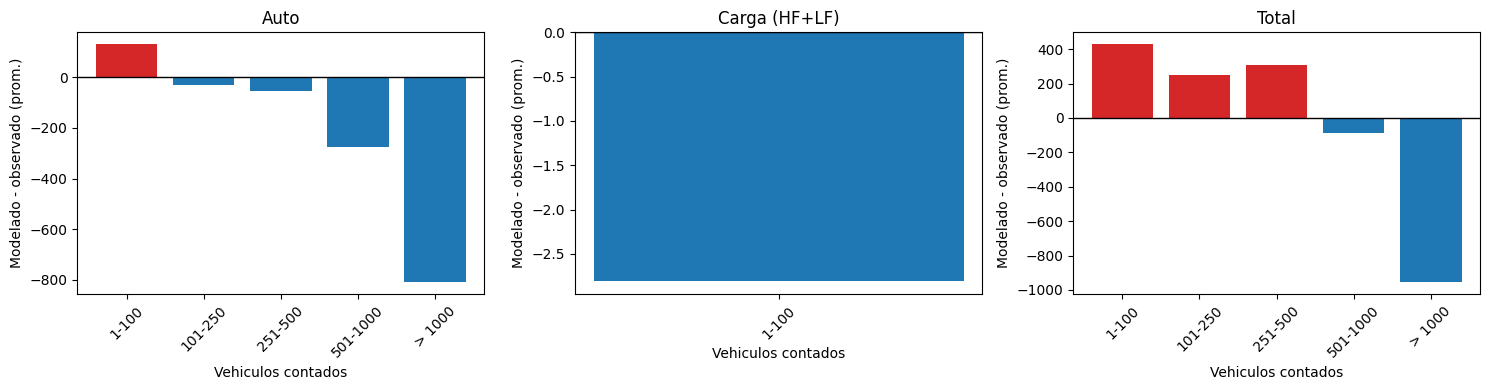

In [41]:
modos = error_nivel["modo"].unique()
fig, axes = plt.subplots(1, len(modos), figsize=(5 * len(modos), 4), squeeze=False)
for ax, m in zip(axes[0], modos):
    d = error_nivel[error_nivel["modo"] == m]
    ax.bar(d["nivel_trafico"].astype(str), d["sesgo_promedio"],
           color=["tab:red" if x > 0 else "tab:blue" for x in d["sesgo_promedio"]])
    ax.axhline(0, color="k", lw=1)
    ax.set_title(m); ax.set_xlabel("Vehiculos contados"); ax.set_ylabel("Modelado - observado (prom.)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 9. Comparacion contra la primera version
Si tienes el Excel de la corrida anterior (`comparacion_volumenes.xlsx`), esta celda compara el % de links con GEH < 5 antes y ahora.

In [44]:
RUTA_ANTERIOR = "/Users/ebonyvaladez/Desktop/Septimo/on campus/comparacion_volumenes.xlsx"   # Excel de la primera version
try:
    ant = pd.read_excel(RUTA_ANTERIOR, sheet_name="4_resumen_por_modo")
    ant["modo"] = ant["modo"].replace({"Carga (HF+LF)": "Carga (HF+LF)", "Carga": "Carga (HF+LF)"})
    ant = ant.set_index(["modo", "periodo"])[["vol_observado_total", "vol_modelado_total", "GEH_mediana", "%_GEH<5"]]
    nuevo = resumen_modo[["vol_observado_total", "vol_modelado_total", "GEH_mediana", "%_GEH<5"]]
    comparacion_versiones = ant.join(nuevo, lsuffix="_v1", rsuffix="_v2")
    comparacion_versiones["cambio_%_GEH<5"] = comparacion_versiones["%_GEH<5_v2"] - comparacion_versiones["%_GEH<5_v1"]
    display(comparacion_versiones.round(2))
except FileNotFoundError:
    comparacion_versiones = pd.DataFrame()
    print("No se encontro el Excel anterior; se omite la comparacion.")

vol_observado_total_v1  vol_modelado_total_v1  \
modo          periodo                                                  
Auto          AP                       400108                 136322   
              LM                       466279                  64895   
              EA                       968277                 117297   
              PP                       463250                 115629   
Carga (HF+LF) AP                         3074                    924   
              LM                         5844                   1521   
              EA                        10173                   1251   
              PP                         2229                    656   

                       GEH_mediana_v1  %_GEH<5_v1  vol_observado_total_v2  \
modo          periodo                                                       
Auto          AP                11.59       14.29                  147109   
              LM                19.56        7.48                  159923   
              EA                20.36        7.80                  187655   
              PP                17.20        8.19                  205779   
Carga (HF+LF) AP                 1.67       97.85                    1116   
              LM                 2.58       84.15                    1992   
              EA                 2.55       86.35                    1980   
              PP                 1.63       96.31                     978   

                       vol_modelado_total_v2  GEH_mediana_v2  %_GEH<5_v2  \
modo          periodo                                                      
Auto          AP                      149081            5.86       43.20   
              LM                       68187            8.70       27.89   
              EA                      124886            5.97       42.47   
              PP                      124947            9.47       24.57   
Carga (HF+LF) AP                         711            1.10       98.51   
              LM                        1315            1.55       97.99   
              EA                        1054            1.00       98.80   
              PP                         513            1.28       98.89   

                       cambio_%_GEH<5  
modo          periodo                  
Auto          AP                28.91  
              LM                20.41  
              EA                34.67  
              PP                16.38  
Carga (HF+LF) AP                 0.66  
              LM                13.84  
              EA                12.45  
              PP                 2.58

## 10. Exportar

In [ ]:
with pd.ExcelWriter("/Users/ebonyvaladez/Desktop/Septimo/on campus/comparacion_volumenes_v2.xlsx") as xw:
    revision.to_excel(xw, sheet_name="0_columnas_usadas", index=False)
    tabla_resumen_links.to_excel(xw, sheet_name="1_resumen_links")
    tabla_auto.to_excel(xw, sheet_name="2_auto_por_link", index=False)
    tabla_carga.to_excel(xw, sheet_name="3_carga_por_link", index=False)
    resumen_modo.to_excel(xw, sheet_name="4_resumen_por_modo")
    tabla_total.to_excel(xw, sheet_name="5_total_por_link", index=False)
    resumen_total.to_excel(xw, sheet_name="6_resumen_total")
    stats_basicas.to_excel(xw, sheet_name="7_estadisticas")
    error_nivel.to_excel(xw, sheet_name="8_error_por_nivel", index=False)
    error_tipo.to_excel(xw, sheet_name="9_error_por_tipo", index=False)
    if len(comparacion_versiones):
        comparacion_versiones.to_excel(xw, sheet_name="10_v1_vs_v2")
print("Listo: comparacion_volumenes_v2.xlsx")

Listo: comparacion_volumenes_v2.xlsx
